# Video Object and Face Detection Using YOLO

## 1. Introduction

This notebook implements video-based object and face detection using
YOLO models and OpenCV.

Unlike image detection, which processes a single image, video detection
requires processing a sequence of frames.

The notebook uses two independent detection models:

1. YOLO general object detection model.
2. Dedicated YOLO face detection model.

Each video frame can be processed using one model or both models.

The notebook covers:

- Video loading and metadata inspection.
- Frame extraction.
- Object detection on video frames.
- Face detection on video frames.
- Combined object and face detection.
- Annotated video generation.
- Video encoding and saving.
- Processing FPS and inference-time measurement.
- Detection statistics.
- Output video verification.
- Performance analysis.

The objective is to create a reusable video-processing workflow
that can later be integrated into the project's Python application.

## 2. Problem Statement

Processing a video requires more than running a detection model once.

A video contains multiple frames that must be decoded, processed,
annotated, and encoded into an output file.

The application must:

1. Open the input video.
2. Read its metadata.
3. Extract frames sequentially.
4. Run the selected detection model or models.
5. Draw predictions on each frame.
6. Write processed frames into an output video.
7. Track processing statistics.
8. Release video resources.

The final result should be a playable video containing the detection
annotations.

### Expected outputs

- Original video metadata.
- Sample extracted frames.
- Object detection video.
- Face detection video.
- Combined detection video.
- Detection statistics.
- Processing performance summary.
- Verified output video files.

## 3. Learning Objectives

After completing this notebook, you should understand:

1. How to open video files using OpenCV.
2. How to inspect video metadata.
3. How to read video frames sequentially.
4. How to run YOLO inference on video frames.
5. How to process video using separate detection models.
6. How to generate annotated videos.
7. How to configure video codecs and output resolution.
8. How to calculate video-processing FPS.
9. How to measure model inference time.
10. How to collect detection statistics across frames.
11. How to handle video processing errors.
12. How to verify the generated video.

## 4. Technical Concepts

### 4.1 Video

A video is a sequence of images displayed over time.

Each image in the sequence is called a frame.

### 4.2 Frame Rate

Frame rate is the number of frames displayed per second.

It is commonly measured in FPS.

For example, a video with 30 FPS is intended to display approximately
30 frames per second.

### 4.3 Video Resolution

Video resolution represents the width and height of each frame.

For example:

- 640 × 480
- 1280 × 720
- 1920 × 1080

Higher resolution can preserve more visual detail but can increase
processing and storage requirements.

### 4.4 Video Processing FPS

Processing FPS measures how many frames the application processes
per second.

It may differ from the original video's FPS.

If a 30 FPS video is processed at 12 FPS, the processing operation
takes longer than real-time playback.

### 4.5 VideoWriter

OpenCV VideoWriter encodes processed frames into an output video.

The output writer requires:

- Output file path.
- Codec.
- Frame rate.
- Frame dimensions.

Every frame written to a VideoWriter must have the configured dimensions.

### 4.6 Detection Statistics

Detection statistics can be collected across frames.

A detection count across a video represents the total number of
predicted bounding boxes, not the number of unique real-world objects
or individuals.

## 5. Video Detection Workflow

The processing workflow is:

1. Configure the project.
2. Validate the model checkpoints.
3. Validate the input video.
4. Inspect video metadata.
5. Extract sample frames.
6. Load both YOLO models.
7. Configure the detection mode.
8. Process video frames sequentially.
9. Annotate each frame.
10. Write the output video.
11. Collect detection statistics.
12. Calculate processing performance.
13. Verify the output files.
14. Inspect the generated videos.

### Detection modes

| Mode | Processing |
|---|---|
| object | General object detection |
| face | Face detection |
| combined | Both models independently |

## 6. Environment Setup

This notebook uses the existing project environment.

Required libraries:

- Ultralytics
- OpenCV
- PyTorch
- NumPy
- Pandas
- Matplotlib
- pathlib
- time
- collections

The notebook does not require a separate environment.

In [43]:
import sys
import platform

print("Python version:", sys.version)
print("Platform:", platform.platform())

Python version: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
Platform: Windows-11-10.0.26300-SP0


### 6.1 Import Required Libraries

Import the libraries required for video processing, inference,
visualization, and analysis.

In [44]:
from pathlib import Path
from collections import Counter
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from IPython.display import display, Video
from ultralytics import YOLO

### 6.2 Verify Library Versions

Check the installed versions to help reproduce the experiments.

In [45]:
import ultralytics
import matplotlib

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)

PyTorch: 2.15.0+cu132
Ultralytics: 8.4.190
OpenCV: 5.0.0
NumPy: 2.5.4
Pandas: 3.1.1
Matplotlib: 3.11.2


### 6.3 Check Hardware Availability

Select CUDA device 0 when available.

Otherwise, use the CPU.

In [46]:
CUDA_AVAILABLE = torch.cuda.is_available()

if CUDA_AVAILABLE:
    DEVICE = 0

    print("CUDA available:", CUDA_AVAILABLE)
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    DEVICE = "cpu"

    print("CUDA available:", CUDA_AVAILABLE)
    print("Using CPU.")

print("Selected device:", DEVICE)

CUDA available: True
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
CUDA version: 13.2
Selected device: 0


## 7. Project Configuration

The notebook uses the existing repository structure.

Expected files:

- models/yolov8n.pt
- models/yolov8m-face.pt
- assets/demo-videos/input-video.mp4

Generated files will be stored in:

- outputs/video-detection/

In [47]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODELS_DIR = PROJECT_ROOT / "models"

DEMO_VIDEOS_DIR = (
    PROJECT_ROOT / "assets" / "demo-videos"
)

OUTPUT_DIR = (
    PROJECT_ROOT / "outputs" / "video-detection"
)

OBJECT_MODEL_PATH = MODELS_DIR / "yolov8n.pt"
FACE_MODEL_PATH = MODELS_DIR / "yolov8m-face.pt"

INPUT_VIDEO_PATH = (
    DEMO_VIDEOS_DIR / "input-video.mp4"
)

print("Project root:", PROJECT_ROOT)
print("Models directory:", MODELS_DIR)
print("Input video:", INPUT_VIDEO_PATH)
print("Output directory:", OUTPUT_DIR)

Project root: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection
Models directory: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\models
Input video: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\assets\demo-videos\input-video.mp4
Output directory: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\outputs\video-detection


### 7.1 Validate Required Files

Verify that both model checkpoints and the input video exist.

In [48]:
required_files = {
    "Object model": OBJECT_MODEL_PATH,
    "Face model": FACE_MODEL_PATH,
    "Input video": INPUT_VIDEO_PATH,
}

missing_files = []

for name, path in required_files.items():
    if path.is_file():
        print(f"FOUND: {name} -> {path}")
    else:
        print(f"MISSING: {name} -> {path}")
        missing_files.append(name)

if missing_files:
    raise FileNotFoundError(
        "Missing required files: "
        + ", ".join(missing_files)
    )

if INPUT_VIDEO_PATH.stat().st_size == 0:
    raise ValueError("The input video file is empty.")

FOUND: Object model -> d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\models\yolov8n.pt
FOUND: Face model -> d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\models\yolov8m-face.pt
FOUND: Input video -> d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\assets\demo-videos\input-video.mp4


### 7.2 Configure Detection Settings

Configure the independent confidence thresholds and YOLO inference size.

The output video will use the original video's dimensions and frame rate
unless explicitly configured otherwise.

The notebook processes every frame by default.

In [49]:
OBJECT_CONFIDENCE = 0.40
FACE_CONFIDENCE = 0.40

IMAGE_SIZE = 640

DETECTION_MODE = "combined"

MAX_FRAMES = None

OUTPUT_CODEC = "mp4v"

print("Object confidence:", OBJECT_CONFIDENCE)
print("Face confidence:", FACE_CONFIDENCE)
print("Inference size:", IMAGE_SIZE)
print("Detection mode:", DETECTION_MODE)
print("Maximum frames:", MAX_FRAMES)

Object confidence: 0.4
Face confidence: 0.4
Inference size: 640
Detection mode: combined
Maximum frames: None


## 8. Load and Inspect the Input Video

OpenCV VideoCapture is used to read the video.

Before processing, inspect:

- Frame width.
- Frame height.
- Frame rate.
- Total frame count.
- Duration.
- File size.

Video metadata helps us understand the input and configure the output writer.

In [50]:
def get_video_metadata(video_path):
    """
    Extract metadata from a video file.

    Parameters
    ----------
    video_path : str or Path
        Input video path.

    Returns
    -------
    dict
        Video metadata.
    """
    video_path = Path(video_path)

    if not video_path.is_file():
        raise FileNotFoundError(video_path)

    capture = cv2.VideoCapture(str(video_path))

    if not capture.isOpened():
        capture.release()
        raise RuntimeError(
            f"Unable to open video: {video_path}"
        )

    try:
        width = int(
            capture.get(cv2.CAP_PROP_FRAME_WIDTH)
        )

        height = int(
            capture.get(cv2.CAP_PROP_FRAME_HEIGHT)
        )

        fps = float(
            capture.get(cv2.CAP_PROP_FPS)
        )

        frame_count = int(
            capture.get(cv2.CAP_PROP_FRAME_COUNT)
        )

        duration = (
            frame_count / fps
            if fps > 0
            else 0.0
        )

        return {
            "file_name": video_path.name,
            "width": width,
            "height": height,
            "fps": fps,
            "frame_count": frame_count,
            "duration_seconds": duration,
            "file_size_bytes": video_path.stat().st_size,
        }

    finally:
        capture.release()

In [51]:
video_metadata = get_video_metadata(
    INPUT_VIDEO_PATH
)

video_metadata_df = pd.DataFrame(
    video_metadata.items(),
    columns=["Property", "Value"],
)

display(video_metadata_df)

,Property,Value
0,file_name,input-video.mp4
1,width,2160
2,height,3840
3,fps,30.0
4,frame_count,936
5,duration_seconds,31.2
6,file_size_bytes,151470473


### 8.1 Calculate Video Properties

Duration is estimated using:

Duration = Total Frames / Original FPS

This calculation assumes that the reported frame rate is valid.

If the frame rate is unavailable or zero, duration cannot be calculated
using this method.

In [52]:
VIDEO_WIDTH = video_metadata["width"]
VIDEO_HEIGHT = video_metadata["height"]
VIDEO_FPS = video_metadata["fps"]
VIDEO_FRAME_COUNT = video_metadata["frame_count"]
VIDEO_DURATION = video_metadata["duration_seconds"]

print("Video width:", VIDEO_WIDTH)
print("Video height:", VIDEO_HEIGHT)
print("Video FPS:", VIDEO_FPS)
print("Total frames:", VIDEO_FRAME_COUNT)
print("Duration:", round(VIDEO_DURATION, 2), "seconds")

if VIDEO_WIDTH <= 0 or VIDEO_HEIGHT <= 0:
    raise ValueError("Invalid video dimensions.")

if VIDEO_FPS <= 0:
    raise ValueError(
        "Invalid video FPS. Cannot safely configure the output writer."
    )

if VIDEO_FRAME_COUNT <= 0:
    raise ValueError("The video contains no readable frames.")

Video width: 2160
Video height: 3840
Video FPS: 30.0
Total frames: 936
Duration: 31.2 seconds


## 9. Extract Sample Frames

A video can be inspected by extracting individual frames.

We will extract frames at selected positions:

- Beginning.
- Approximately 25%.
- Approximately 50%.
- Approximately 75%.
- End.

Frame extraction helps us inspect the video before running the full
detection pipeline.

In [53]:
def extract_video_frames(
    video_path,
    positions=(0.0, 0.25, 0.50, 0.75, 1.0),
):
    """
    Extract frames at relative positions in a video.

    Positions are values between 0 and 1.
    """
    metadata = get_video_metadata(video_path)

    capture = cv2.VideoCapture(str(video_path))

    if not capture.isOpened():
        capture.release()
        raise RuntimeError("Unable to open input video.")

    extracted_frames = []

    try:
        total_frames = metadata["frame_count"]

        for position in positions:
            if not 0 <= position <= 1:
                raise ValueError(
                    "Frame positions must be between 0 and 1."
                )

            frame_index = min(
                int(position * (total_frames - 1)),
                total_frames - 1,
            )

            capture.set(
                cv2.CAP_PROP_POS_FRAMES,
                frame_index,
            )

            success, frame = capture.read()

            if success:
                extracted_frames.append(
                    {
                        "position": position,
                        "frame_index": frame_index,
                        "frame": frame,
                    }
                )
            else:
                print(
                    f"Unable to extract frame {frame_index}."
                )

    finally:
        capture.release()

    return extracted_frames

In [54]:
sample_frames = extract_video_frames(
    INPUT_VIDEO_PATH
)

print("Successfully extracted:", len(sample_frames))

for sample in sample_frames:
    print(
        "Frame:",
        sample["frame_index"],
        "| Position:",
        sample["position"],
    )

Successfully extracted: 5
Frame: 0 | Position: 0.0
Frame: 233 | Position: 0.25
Frame: 467 | Position: 0.5
Frame: 701 | Position: 0.75
Frame: 935 | Position: 1.0


### 9.1 Visualize Extracted Frames

Display the extracted frames to understand the input video's content.

All frames are converted from BGR to RGB before Matplotlib visualization.

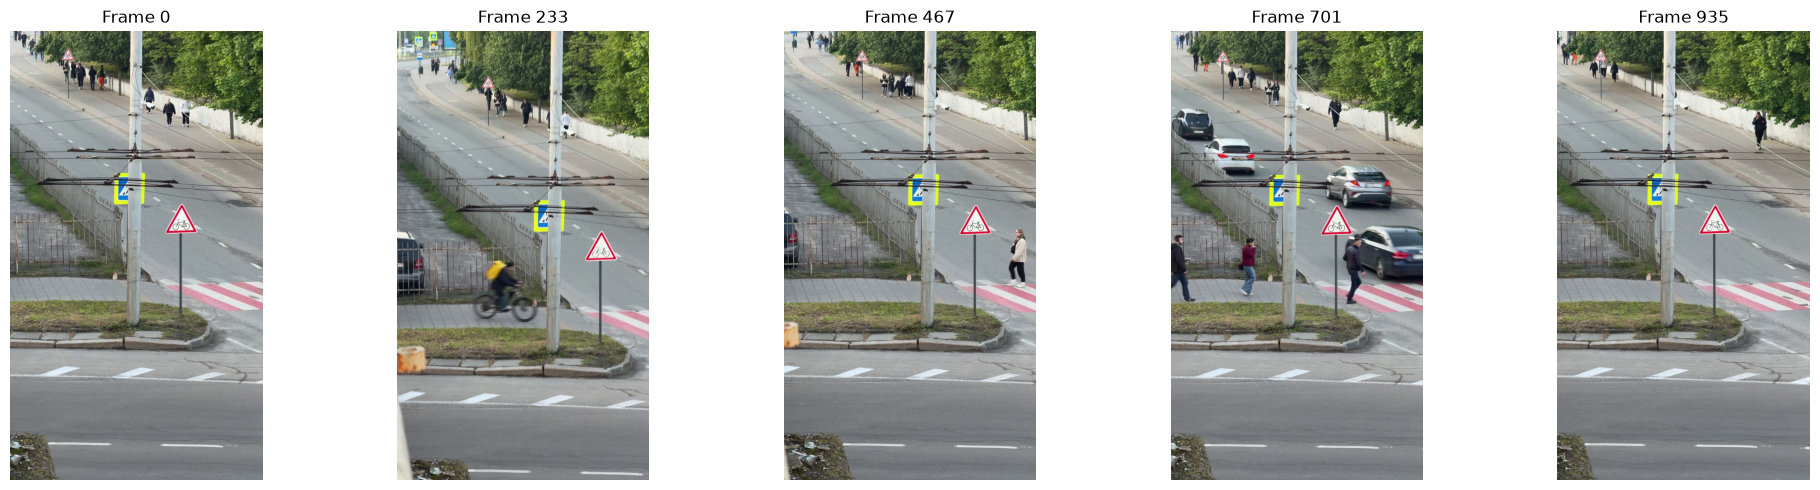

In [55]:
if not sample_frames:
    raise RuntimeError(
        "No sample frames could be extracted."
    )

fig, axes = plt.subplots(
    1,
    len(sample_frames),
    figsize=(20, 5),
)

if len(sample_frames) == 1:
    axes = [axes]

for axis, sample in zip(axes, sample_frames):
    frame_rgb = cv2.cvtColor(
        sample["frame"],
        cv2.COLOR_BGR2RGB,
    )

    axis.imshow(frame_rgb)

    axis.set_title(
        f"Frame {sample['frame_index']}"
    )

    axis.axis("off")

plt.tight_layout()
plt.show()

## 10. Load YOLO Models

Load the two existing detection checkpoints.

Both models are loaded once and reused for all video frames.

Repeatedly loading model weights inside the processing loop would introduce
unnecessary overhead.

In [56]:
object_model = YOLO(str(OBJECT_MODEL_PATH))
face_model = YOLO(str(FACE_MODEL_PATH))

print("Object model loaded:", OBJECT_MODEL_PATH.name)
print("Face model loaded:", FACE_MODEL_PATH.name)

Object model loaded: yolov8n.pt
Face model loaded: yolov8m-face.pt


### 10.1 Inspect Model Information

Display the model task and supported class names.

In [57]:
print("OBJECT MODEL")
print("Task:", object_model.task)
print("Classes:", object_model.names)

print("\nFACE MODEL")
print("Task:", face_model.task)
print("Classes:", face_model.names)

OBJECT MODEL
Task: detect
Classes: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keybo

## 11. Frame Processing Pipeline

Each frame is processed independently.

The selected mode determines which detection model or models are executed.

The returned annotated frame is used by the video writer.

We also collect structured detections for later analysis.

In [58]:
def synchronize_device():
    """
    Synchronize CUDA operations before and after timed operations.
    """
    if torch.cuda.is_available():
        torch.cuda.synchronize()

In [59]:
def process_video_frame(
    frame,
    mode="combined",
    object_confidence=0.40,
    face_confidence=0.40,
    imgsz=640,
    device=DEVICE,
):
    """
    Process one video frame using the selected detection mode.

    Returns
    -------
    annotated_frame : numpy.ndarray
        Annotated frame in BGR format.

    results : dict
        Individual YOLO results.

    inference_time : float
        Time spent in model prediction operations.
    """
    if frame is None or frame.size == 0:
        raise ValueError("Input frame is empty.")

    if mode not in {"object", "face", "combined"}:
        raise ValueError(
            "Invalid mode. Use object, face, or combined."
        )

    annotated_frame = frame.copy()
    results = {}

    synchronize_device()
    start_time = time.perf_counter()

    if mode in {"object", "combined"}:
        object_predictions = object_model.predict(
            source=frame,
            conf=object_confidence,
            imgsz=imgsz,
            device=device,
            verbose=False,
        )

        results["object"] = object_predictions[0]

        annotated_frame = results["object"].plot(
            img=annotated_frame
        )

    if mode in {"face", "combined"}:
        face_predictions = face_model.predict(
            source=frame,
            conf=face_confidence,
            imgsz=imgsz,
            device=device,
            verbose=False,
        )

        results["face"] = face_predictions[0]

        annotated_frame = results["face"].plot(
            img=annotated_frame
        )

    synchronize_device()

    inference_time = (
        time.perf_counter() - start_time
    )

    return (
        annotated_frame,
        results,
        inference_time,
    )

In [60]:
def extract_frame_detections(results, frame_index):
    """
    Extract detections from a frame's YOLO results.

    Detector name is retained to distinguish the independent
    class namespaces of the two models.
    """
    detections = []

    for detector_name, result in results.items():
        if result.boxes is None:
            continue

        for box in result.boxes:
            class_id = int(box.cls.item())
            confidence = float(box.conf.item())

            x1, y1, x2, y2 = (
                box.xyxy[0].cpu().numpy().tolist()
            )

            detections.append(
                {
                    "frame_index": frame_index,
                    "detector": detector_name,
                    "class_id": class_id,
                    "class_name": result.names[class_id],
                    "confidence": confidence,
                    "x1": float(x1),
                    "y1": float(y1),
                    "x2": float(x2),
                    "y2": float(y2),
                }
            )

    return detections

### 11.1 Draw Performance Information

Display the current processing FPS and frame number on the output video.

The processing FPS is based on completed frame-processing iterations.
It is not the original video's playback FPS.

In [61]:
def annotate_video_status(
    frame,
    frame_index,
    processing_fps,
    mode,
):
    """
    Draw processing status on an annotated BGR frame.
    """
    output = frame.copy()

    cv2.rectangle(
        output,
        (10, 10),
        (390, 95),
        (0, 0, 0),
        thickness=-1,
    )

    cv2.putText(
        output,
        f"Mode: {mode}",
        (20, 38),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.65,
        (255, 255, 0),
        2,
        cv2.LINE_AA,
    )

    cv2.putText(
        output,
        f"Frame: {frame_index}",
        (20, 62),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.55,
        (255, 255, 255),
        1,
        cv2.LINE_AA,
    )

    cv2.putText(
        output,
        f"Processing FPS: {processing_fps:.2f}",
        (20, 84),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.55,
        (0, 255, 0),
        1,
        cv2.LINE_AA,
    )

    return output

## 12. Video Processing Function

This is the main video-processing implementation.

It performs the following operations:

1. Opens the input video.
2. Reads its properties.
3. Initializes the output video writer.
4. Reads frames sequentially.
5. Runs the selected detection pipeline.
6. Annotates each frame.
7. Writes the processed frame.
8. Collects detection information.
9. Calculates processing statistics.
10. Releases all resources.

The function supports a maximum frame limit for testing shorter videos.

When MAX_FRAMES is None, all readable frames are processed.

The original video is never modified.

In [62]:
def process_video(
    input_path,
    output_path,
    mode="combined",
    object_confidence=0.40,
    face_confidence=0.40,
    imgsz=640,
    device=DEVICE,
    max_frames=None,
    codec="mp4v",
    display_progress=True,
):
    """
    Process a video using YOLO object detection, face detection,
    or both independent models.

    Parameters
    ----------
    input_path : str or Path
        Input video file.

    output_path : str or Path
        Destination for the annotated video.

    mode : str
        object, face, or combined.

    object_confidence : float
        Confidence threshold for the object detection model.

    face_confidence : float
        Confidence threshold for the face detection model.

    imgsz : int
        YOLO inference image size.

    device : int or str
        Inference device.

    max_frames : int or None
        Maximum number of frames to process.

    codec : str
        Four-character OpenCV video codec.

    display_progress : bool
        Whether to print progress information.

    Returns
    -------
    dict
        Processing statistics and detection records.
    """
    input_path = Path(input_path)
    output_path = Path(output_path)

    if not input_path.is_file():
        raise FileNotFoundError(input_path)

    if mode not in {"object", "face", "combined"}:
        raise ValueError(
            "mode must be object, face, or combined."
        )

    if len(codec) != 4:
        raise ValueError(
            "The video codec must contain exactly four characters."
        )

    if max_frames is not None and max_frames <= 0:
        raise ValueError(
            "max_frames must be a positive integer or None."
        )

    output_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    capture = None
    writer = None

    frame_index = 0
    detection_records = []
    inference_times = []
    frame_processing_times = []

    detection_counter = Counter()

    total_start = time.perf_counter()

    metadata = get_video_metadata(input_path)

    source_fps = metadata["fps"]
    frame_width = metadata["width"]
    frame_height = metadata["height"]

    if source_fps <= 0:
        raise ValueError(
            "Input video has an invalid frame rate."
        )

    if frame_width <= 0 or frame_height <= 0:
        raise ValueError(
            "Input video has invalid frame dimensions."
        )

    try:
        capture = cv2.VideoCapture(
            str(input_path)
        )

        if not capture.isOpened():
            raise RuntimeError(
                f"Unable to open input video: {input_path}"
            )

        fourcc = cv2.VideoWriter_fourcc(
            *codec
        )

        writer = cv2.VideoWriter(
            str(output_path),
            fourcc,
            source_fps,
            (frame_width, frame_height),
        )

        if not writer.isOpened():
            raise RuntimeError(
                f"Unable to initialize video writer: {output_path}"
            )

        if display_progress:
            print("Starting video processing.")
            print("Input:", input_path)
            print("Output:", output_path)
            print("Mode:", mode)
            print("Source FPS:", source_fps)
            print(
                "Resolution:",
                frame_width,
                "x",
                frame_height,
            )

        while True:
            if (
                max_frames is not None
                and frame_index >= max_frames
            ):
                break

            frame_start = time.perf_counter()

            success, frame = capture.read()

            if not success:
                break

            annotated_frame, results, inference_time = (
                process_video_frame(
                    frame=frame,
                    mode=mode,
                    object_confidence=object_confidence,
                    face_confidence=face_confidence,
                    imgsz=imgsz,
                    device=device,
                )
            )

            inference_times.append(inference_time)

            current_detections = extract_frame_detections(
                results,
                frame_index,
            )

            detection_records.extend(
                current_detections
            )

            for detection in current_detections:
                detection_counter[
                    (
                        detection["detector"],
                        detection["class_name"],
                    )
                ] += 1

            elapsed_frame_time = (
                time.perf_counter() - frame_start
            )

            frame_processing_times.append(
                elapsed_frame_time
            )

            current_fps = (
                1.0 / elapsed_frame_time
                if elapsed_frame_time > 0
                else 0.0
            )

            output_frame = annotate_video_status(
                frame=annotated_frame,
                frame_index=frame_index,
                processing_fps=current_fps,
                mode=mode,
            )

            if output_frame.shape[:2] != (
                frame_height,
                frame_width,
            ):
                raise ValueError(
                    "Processed frame dimensions do not match "
                    "the configured video writer dimensions."
                )

            writer.write(output_frame)

            frame_index += 1

            if (
                display_progress
                and frame_index % 100 == 0
            ):
                print(
                    f"Processed {frame_index} frames..."
                )

    finally:
        if capture is not None:
            capture.release()

        if writer is not None:
            writer.release()

    total_runtime = (
        time.perf_counter() - total_start
    )

    if frame_index == 0:
        raise RuntimeError(
            "No frames were successfully processed."
        )

    detection_df = pd.DataFrame(
        detection_records
    )

    average_inference_time = (
        float(np.mean(inference_times))
        if inference_times
        else 0.0
    )

    average_frame_time = (
        float(np.mean(frame_processing_times))
        if frame_processing_times
        else 0.0
    )

    summary = {
        "mode": mode,
        "input_path": str(input_path),
        "output_path": str(output_path),
        "frames_processed": frame_index,
        "source_fps": source_fps,
        "width": frame_width,
        "height": frame_height,
        "total_runtime_seconds": total_runtime,
        "processing_fps": (
            frame_index / total_runtime
            if total_runtime > 0
            else 0.0
        ),
        "average_inference_seconds": (
            average_inference_time
        ),
        "median_inference_seconds": (
            float(np.median(inference_times))
            if inference_times
            else 0.0
        ),
        "average_frame_processing_seconds": (
            average_frame_time
        ),
        "detection_counts": dict(detection_counter),
        "detections": detection_df,
    }

    if display_progress:
        print("\nVideo processing completed.")
        print("Frames processed:", frame_index)
        print(
            f"Runtime: {total_runtime:.2f} seconds"
        )
        print(
            f"Processing FPS: {summary['processing_fps']:.2f}"
        )
        print("Output:", output_path)

    return summary

### 12.1 Understand the Processing Function

The processing function returns a dictionary containing:

| Metric | Description |
|---|---|
| mode | Detection mode |
| frames_processed | Number of successfully processed frames |
| source_fps | Original video's FPS |
| processing_fps | Frames processed per second |
| average_inference_seconds | Mean model inference duration |
| median_inference_seconds | Median model inference duration |
| average_frame_processing_seconds | Mean full frame processing duration |
| detection_counts | Total predicted boxes grouped by detector and class |
| detections | Structured detection DataFrame |

The processing FPS includes frame reading, inference, annotation,
and writing operations.

The inference time measures only the model prediction operations.

The output video retains the source video's nominal FPS. If processing
is slower than playback, the output may take longer to generate than
the original video duration.

In [63]:
def display_video_summary(summary):
    """
    Display the main metrics from a video-processing session.
    """
    summary_data = {
        "Detection mode": summary["mode"],
        "Frames processed": summary["frames_processed"],
        "Source FPS": summary["source_fps"],
        "Resolution": (
            f"{summary['width']}x{summary['height']}"
        ),
        "Runtime (seconds)": summary["total_runtime_seconds"],
        "Processing FPS": summary["processing_fps"],
        "Average inference (seconds)": (
            summary["average_inference_seconds"]
        ),
        "Median inference (seconds)": (
            summary["median_inference_seconds"]
        ),
        "Average frame processing (seconds)": (
            summary["average_frame_processing_seconds"]
        ),
    }

    display(
        pd.DataFrame(
            summary_data.items(),
            columns=["Metric", "Value"],
        )
    )

    print("\nDetection counts:")

    if summary["detection_counts"]:
        for (detector, class_name), count in (
            summary["detection_counts"].items()
        ):
            print(
                f"{detector} | {class_name}: {count}"
            )
    else:
        print("No detections were recorded.")

## 13. Experiment 1: Video Object Detection

This experiment processes the input video using only the general
object detection model.

The output contains:

- Object bounding boxes.
- Class labels.
- Confidence scores.
- Frame number.
- Processing FPS.

The annotated video is saved separately from the original input.

For the first execution, consider using MAX_FRAMES = 300 to validate
the pipeline before processing the entire video.

After confirming that the output works, set MAX_FRAMES = None.

In [64]:
object_video_path = (
    OUTPUT_DIR / "object-detection.mp4"
)

object_video_summary = process_video(
    input_path=INPUT_VIDEO_PATH,
    output_path=object_video_path,
    mode="object",
    object_confidence=OBJECT_CONFIDENCE,
    imgsz=IMAGE_SIZE,
    device=DEVICE,
    max_frames=MAX_FRAMES,
    codec=OUTPUT_CODEC,
)

display_video_summary(
    object_video_summary
)

Starting video processing.
Input: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\assets\demo-videos\input-video.mp4
Output: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\outputs\video-detection\object-detection.mp4
Mode: object
Source FPS: 30.0
Resolution: 2160 x 3840
Processed 100 frames...
Processed 200 frames...
Processed 300 frames...
Processed 400 frames...
Processed 500 frames...
Processed 600 frames...
Processed 700 frames...
Processed 800 frames...
Processed 900 frames...

Video processing completed.
Frames processed: 936
Runtime: 84.70 seconds
Processing FPS: 11.05
Output: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\outputs\video-detection\object-detection.mp4


,Metric,Value
0,Detection mode,object
1,Frames processed,936
2,Source FPS,30.0
3,Resolution,2160x3840
4,Runtime (seconds),84.695405
5,Processing FPS,11.051367
6,Average inference (seconds),0.021502
7,Median inference (seconds),0.021776
8,Average frame processing (seconds),0.042144



Detection counts:
object | person: 5738
object | traffic light: 12
object | car: 905
object | truck: 9
object | bicycle: 17
object | motorcycle: 7
object | horse: 1


## 14. Experiment 2: Video Face Detection

This experiment processes the same input video using only the
dedicated face detection model.

The model attempts to locate faces in each frame.

Face detection is not identity recognition.

The output video is saved independently from the object detection video.

In [65]:
face_video_path = (
    OUTPUT_DIR / "face-detection.mp4"
)

face_video_summary = process_video(
    input_path=INPUT_VIDEO_PATH,
    output_path=face_video_path,
    mode="face",
    face_confidence=FACE_CONFIDENCE,
    imgsz=IMAGE_SIZE,
    device=DEVICE,
    max_frames=MAX_FRAMES,
    codec=OUTPUT_CODEC,
)

display_video_summary(
    face_video_summary
)

Starting video processing.
Input: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\assets\demo-videos\input-video.mp4
Output: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\outputs\video-detection\face-detection.mp4
Mode: face
Source FPS: 30.0
Resolution: 2160 x 3840
Processed 100 frames...
Processed 200 frames...
Processed 300 frames...
Processed 400 frames...
Processed 500 frames...
Processed 600 frames...
Processed 700 frames...
Processed 800 frames...
Processed 900 frames...

Video processing completed.
Frames processed: 936
Runtime: 144.30 seconds
Processing FPS: 6.49
Output: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\outputs\video-detection\face-detection.mp4


,Metric,Value
0,Detection mode,face
1,Frames processed,936
2,Source FPS,30.0
3,Resolution,2160x3840
4,Runtime (seconds),144.296247
5,Processing FPS,6.486655
6,Average inference (seconds),0.04488
7,Median inference (seconds),0.045099
8,Average frame processing (seconds),0.078024



Detection counts:
face | face: 541


## 15. Experiment 3: Combined Object and Face Detection

This experiment runs both YOLO models on each video frame.

Processing sequence:

1. Read a frame.
2. Run general object detection.
3. Draw object predictions.
4. Run face detection on the same original frame.
5. Draw face predictions on the object-annotated frame.
6. Write the combined frame into the output video.

The output provides a combined visualization of the two independent models.

It is not a single merged YOLO model.

In [66]:
combined_video_path = (
    OUTPUT_DIR / "combined-detection.mp4"
)

combined_video_summary = process_video(
    input_path=INPUT_VIDEO_PATH,
    output_path=combined_video_path,
    mode="combined",
    object_confidence=OBJECT_CONFIDENCE,
    face_confidence=FACE_CONFIDENCE,
    imgsz=IMAGE_SIZE,
    device=DEVICE,
    max_frames=MAX_FRAMES,
    codec=OUTPUT_CODEC,
)

display_video_summary(
    combined_video_summary
)

Starting video processing.
Input: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\assets\demo-videos\input-video.mp4
Output: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\outputs\video-detection\combined-detection.mp4
Mode: combined
Source FPS: 30.0
Resolution: 2160 x 3840
Processed 100 frames...
Processed 200 frames...
Processed 300 frames...
Processed 400 frames...
Processed 500 frames...
Processed 600 frames...
Processed 700 frames...
Processed 800 frames...
Processed 900 frames...

Video processing completed.
Frames processed: 936
Runtime: 138.01 seconds
Processing FPS: 6.78
Output: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\outputs\video-detection\combined-detection.mp4


,Metric,Value
0,Detection mode,combined
1,Frames processed,936
2,Source FPS,30.0
3,Resolution,2160x3840
4,Runtime (seconds),138.008219
5,Processing FPS,6.782205
6,Average inference (seconds),0.064063
7,Median inference (seconds),0.062802
8,Average frame processing (seconds),0.088555



Detection counts:
object | person: 5738
face | face: 541
object | traffic light: 12
object | car: 905
object | truck: 9
object | bicycle: 17
object | motorcycle: 7
object | horse: 1


## 16. Compare Video Detection Experiments

All three experiments use the same input video.

We compare:

- Number of frames processed.
- Total processing runtime.
- Processing FPS.
- Average inference duration.
- Number of detections.

The combined mode runs two models per frame and may therefore require
more computation.

However, actual performance must be measured rather than assumed.

In [67]:
video_summaries = [
    object_video_summary,
    face_video_summary,
    combined_video_summary,
]

video_comparison_rows = []

for summary in video_summaries:
    video_comparison_rows.append(
        {
            "Mode": summary["mode"],
            "Frames Processed": summary["frames_processed"],
            "Runtime (seconds)": (
                summary["total_runtime_seconds"]
            ),
            "Processing FPS": summary["processing_fps"],
            "Average Inference (seconds)": (
                summary["average_inference_seconds"]
            ),
            "Average Frame Time (seconds)": (
                summary["average_frame_processing_seconds"]
            ),
            "Total Detections": sum(
                summary["detection_counts"].values()
            ),
        }
    )

video_comparison_df = pd.DataFrame(
    video_comparison_rows
)

display(video_comparison_df.round(4))

,Mode,Frames Processed,Runtime (seconds),Processing FPS,Average Inference (seconds),Average Frame Time (seconds),Total Detections
0,object,936,84.6954,11.0514,0.0215,0.0421,6689
1,face,936,144.2962,6.4867,0.0449,0.0780,541
2,combined,936,138.0082,6.7822,0.0641,0.0886,7230


### 16.1 Visualize Processing FPS

The following chart compares the measured processing FPS
of each detection mode.

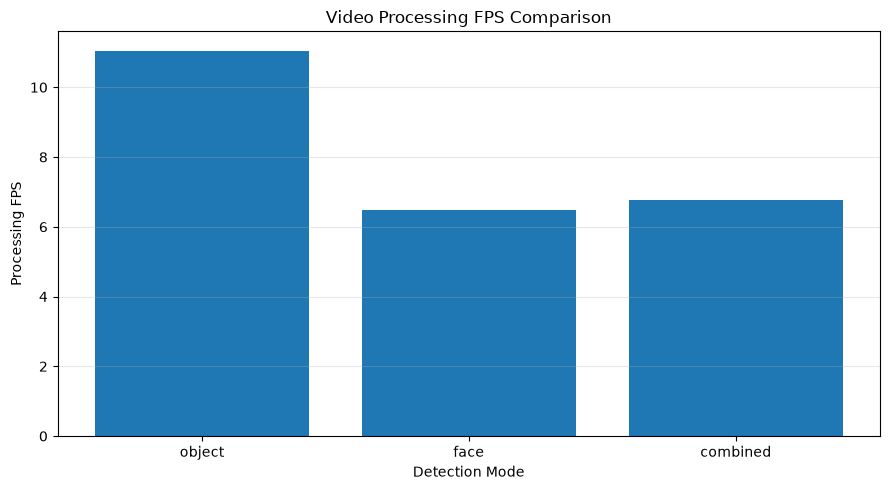

In [68]:
plt.figure(figsize=(9, 5))

plt.bar(
    video_comparison_df["Mode"],
    video_comparison_df["Processing FPS"],
)

plt.title("Video Processing FPS Comparison")
plt.xlabel("Detection Mode")
plt.ylabel("Processing FPS")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 16.2 Visualize Inference Time

Compare the average model inference duration for each detection mode.

Combined inference includes the prediction operations of both models.

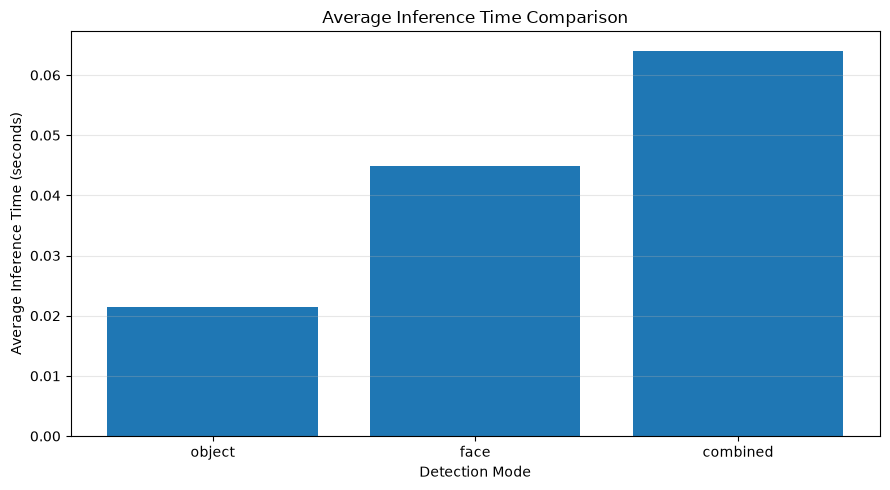

In [69]:
plt.figure(figsize=(9, 5))

plt.bar(
    video_comparison_df["Mode"],
    video_comparison_df["Average Inference (seconds)"],
)

plt.title("Average Inference Time Comparison")
plt.xlabel("Detection Mode")
plt.ylabel("Average Inference Time (seconds)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 16.3 Interpret the Results

Use the measured table and charts to answer:

1. Which detection mode processed the video fastest?
2. Which mode had the highest average inference time?
3. Did combined detection reduce processing FPS?
4. Were there differences in detection counts?
5. Did the output video contain the expected number of frames?

Do not conclude that one model is more accurate based only on processing
time or detection count.

Accuracy requires an appropriate labeled evaluation dataset and
metrics such as precision, recall, and mAP.

## 17. Analyze Detection Results

Each processed frame can contain zero or more detections.

The detection DataFrame stores:

- Frame index.
- Detector name.
- Class ID.
- Class name.
- Confidence.
- Bounding box coordinates.

This makes it possible to analyze detection patterns across the video.

In [70]:
object_video_detections = (
    object_video_summary["detections"]
)

face_video_detections = (
    face_video_summary["detections"]
)

combined_video_detections = (
    combined_video_summary["detections"]
)

print("Object detection records:")
display(object_video_detections.head())

print("Face detection records:")
display(face_video_detections.head())

print("Combined detection records:")
display(combined_video_detections.head())

Object detection records:


,frame_index,detector,class_id,class_name,confidence,x1,y1,x2,y2
0,0,object,0,person,0.815036,668.496460,297.439362,743.206055,510.334167
1,0,object,0,person,0.805617,1309.674561,588.160645,1414.638916,809.178711
2,0,object,0,person,0.715642,563.892578,258.687866,650.191650,501.570068
3,0,object,0,person,0.665070,1459.182617,599.313110,1549.273438,815.738159
4,0,object,0,person,0.655789,1146.859375,473.153320,1238.717896,705.191895


Face detection records:


,frame_index,detector,class_id,class_name,confidence,x1,y1,x2,y2
0,0,face,0,face,0.445471,1337.831055,584.857056,1362.694214,616.942078
1,22,face,0,face,0.450374,1289.597656,586.772217,1313.397827,617.396851
2,24,face,0,face,0.410142,1285.925049,583.987671,1309.594971,613.022217
3,26,face,0,face,0.427103,1280.391113,582.589783,1304.992188,612.832031
4,48,face,0,face,0.465443,1238.510620,579.266418,1263.975098,611.307983


Combined detection records:


,frame_index,detector,class_id,class_name,confidence,x1,y1,x2,y2
0,0,object,0,person,0.815036,668.496460,297.439362,743.206055,510.334167
1,0,object,0,person,0.805617,1309.674561,588.160645,1414.638916,809.178711
2,0,object,0,person,0.715642,563.892578,258.687866,650.191650,501.570068
3,0,object,0,person,0.665070,1459.182617,599.313110,1549.273438,815.738159
4,0,object,0,person,0.655789,1146.859375,473.153320,1238.717896,705.191895


### 17.1 Analyze Class Frequencies

Calculate the total number of predicted bounding boxes for each class.

These values count detections across frames.

They do not count unique objects or track individual objects.

In [71]:
if combined_video_detections.empty:
    print("No detections are available.")
else:
    class_frequency_df = (
        combined_video_detections
        .groupby(
            ["detector", "class_name"]
        )
        .size()
        .reset_index(name="Detection Count")
        .sort_values(
            "Detection Count",
            ascending=False,
        )
    )

    display(class_frequency_df)

,detector,class_name,Detection Count
5,object,person,5738
2,object,car,905
0,face,face,541
1,object,bicycle,17
6,object,traffic light,12
7,object,truck,9
4,object,motorcycle,7
3,object,horse,1


### 17.2 Analyze Confidence Distribution

Examine the confidence distribution of the predictions.

Confidence scores indicate model prediction confidence and should not
be interpreted as direct accuracy measurements.

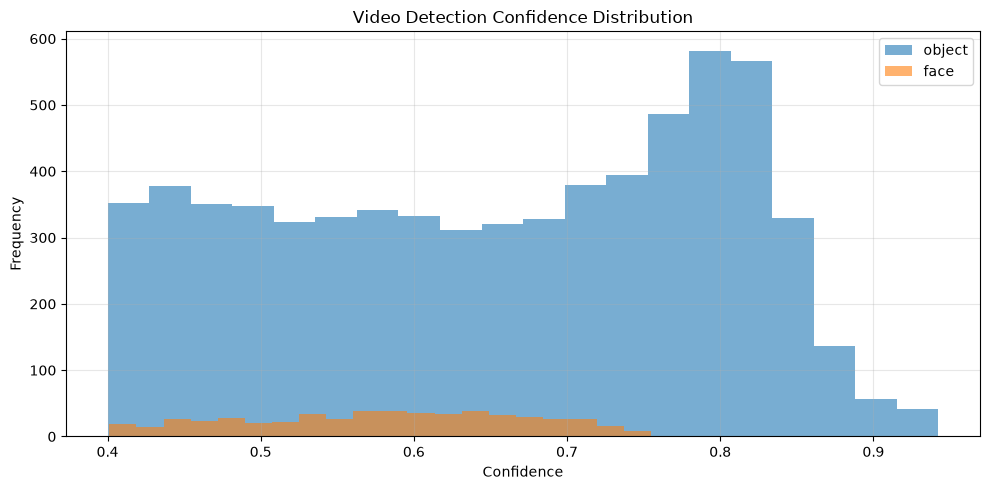

In [72]:
if combined_video_detections.empty:
    print("No confidence values are available.")
else:
    plt.figure(figsize=(10, 5))

    for detector_name in (
        combined_video_detections["detector"].unique()
    ):
        values = combined_video_detections.loc[
            combined_video_detections["detector"]
            == detector_name,
            "confidence",
        ]

        plt.hist(
            values,
            bins=20,
            alpha=0.6,
            label=detector_name,
        )

    plt.title("Video Detection Confidence Distribution")
    plt.xlabel("Confidence")
    plt.ylabel("Frequency")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

### 17.3 Analyze Frame-Level Detection Counts

Count the number of predicted bounding boxes in each video frame.

This helps identify frames containing more or fewer detections.

In [73]:
if combined_video_detections.empty:
    print("No frame-level detection data is available.")
else:
    frame_detection_counts = (
        combined_video_detections
        .groupby("frame_index")
        .size()
        .reindex(
            range(
                combined_video_summary["frames_processed"]
            ),
            fill_value=0,
        )
        .rename("detection_count")
    )

    frame_detection_counts_df = (
        frame_detection_counts.reset_index()
    )

    frame_detection_counts_df.columns = [
        "Frame Index",
        "Detection Count",
    ]

    display(
        frame_detection_counts_df.head(10)
    )

,Frame Index,Detection Count
0,0,8
1,1,7
2,2,7
3,3,7
4,4,6
5,5,6
6,6,6
7,7,6
8,8,6
9,9,6


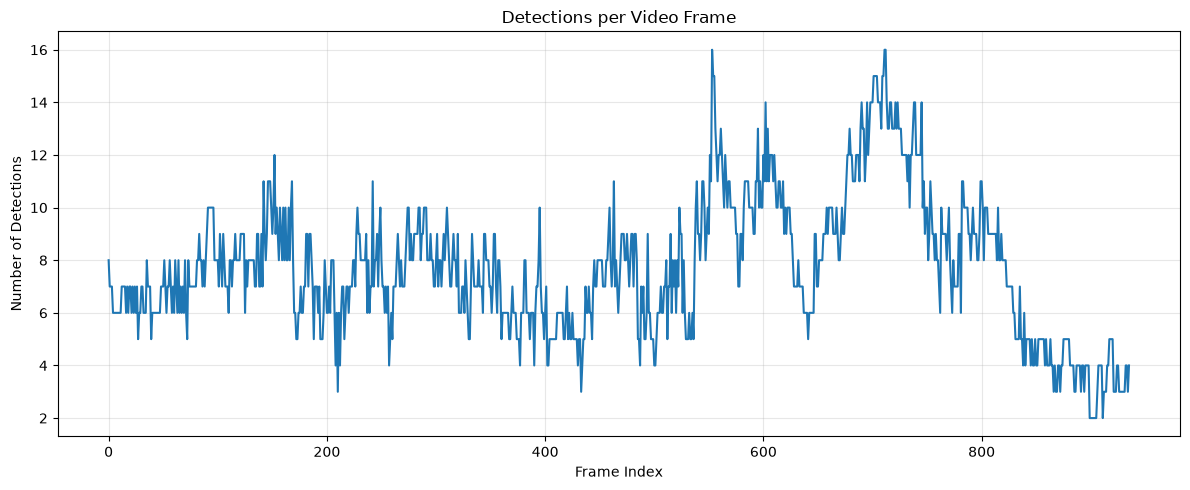

In [74]:
if not combined_video_detections.empty:
    plt.figure(figsize=(12, 5))

    plt.plot(
        frame_detection_counts.index,
        frame_detection_counts.values,
    )

    plt.title("Detections per Video Frame")
    plt.xlabel("Frame Index")
    plt.ylabel("Number of Detections")
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

## 18. Export Detection Results

Export the structured detection records and experiment summaries.

Generated files:

- object-detections.csv
- face-detections.csv
- combined-detections.csv
- video-performance-summary.csv
- frame-detection-counts.csv

These files make the results available for later analysis
and application development.

In [75]:
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

export_datasets = {
    "object-detections.csv": object_video_detections,
    "face-detections.csv": face_video_detections,
    "combined-detections.csv": combined_video_detections,
    "video-performance-summary.csv": video_comparison_df,
}

for filename, dataframe in export_datasets.items():
    output_path = OUTPUT_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
    )

    print("Saved:", output_path)

Saved: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\outputs\video-detection\object-detections.csv
Saved: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\outputs\video-detection\face-detections.csv
Saved: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\outputs\video-detection\combined-detections.csv
Saved: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\outputs\video-detection\video-performance-summary.csv


In [76]:
if "frame_detection_counts_df" in globals():
    frame_counts_path = (
        OUTPUT_DIR / "frame-detection-counts.csv"
    )

    frame_detection_counts_df.to_csv(
        frame_counts_path,
        index=False,
    )

    print("Saved:", frame_counts_path)
else:
    print("Frame-level detection counts were not generated.")

Saved: d:\Learning-Materials\Projects\ML-Projects\Simple-Face-Detection\outputs\video-detection\frame-detection-counts.csv


## 19. Verify Generated Videos

After processing, verify that each output video exists and is readable.

A file existing on disk does not automatically mean that it is a valid
or playable video.

We therefore reopen each output with OpenCV and inspect its metadata.

In [77]:
def verify_output_video(video_path):
    """
    Verify that an output video exists and can be opened.

    Returns
    -------
    dict
        File and video metadata.
    """
    video_path = Path(video_path)

    if not video_path.is_file():
        raise FileNotFoundError(video_path)

    if video_path.stat().st_size == 0:
        raise ValueError(
            f"Output video is empty: {video_path}"
        )

    metadata = get_video_metadata(video_path)

    capture = cv2.VideoCapture(
        str(video_path)
    )

    if not capture.isOpened():
        capture.release()

        raise RuntimeError(
            f"Output video cannot be opened: {video_path}"
        )

    try:
        success, frame = capture.read()

        if not success or frame is None:
            raise RuntimeError(
                f"Unable to read a frame from: {video_path}"
            )

        return {
            "file_name": video_path.name,
            "file_size_bytes": video_path.stat().st_size,
            "width": metadata["width"],
            "height": metadata["height"],
            "fps": metadata["fps"],
            "frame_count": metadata["frame_count"],
            "first_frame_readable": True,
        }

    finally:
        capture.release()

In [78]:
output_video_paths = [
    object_video_path,
    face_video_path,
    combined_video_path,
]

verification_results = []

for output_path in output_video_paths:
    try:
        result = verify_output_video(
            output_path
        )

        verification_results.append(result)

        print(
            "VERIFIED:",
            output_path.name,
        )

    except Exception as error:
        print(
            "VERIFICATION FAILED:",
            output_path.name,
            "|",
            error,
        )

verification_df = pd.DataFrame(
    verification_results
)

display(verification_df)

VERIFIED: object-detection.mp4
VERIFIED: face-detection.mp4
VERIFIED: combined-detection.mp4


,file_name,file_size_bytes,width,height,fps,frame_count,first_frame_readable
0,object-detection.mp4,309400630,2160,3840,30.0,936,True
1,face-detection.mp4,270202226,2160,3840,30.0,936,True
2,combined-detection.mp4,312151181,2160,3840,30.0,936,True


### 19.1 Preview the Combined Detection Video

Use the notebook's video display functionality to preview the generated
combined detection video.

Depending on the video size and notebook environment, playback may
take additional time or require a compatible browser codec.

In [79]:
if combined_video_path.exists():
    display(
        Video(
            filename=str(combined_video_path),
            embed=False,
        )
    )
else:
    print("Combined output video does not exist.")

### 19.2 Extract and Display an Annotated Output Frame

For a simpler inspection, extract the first frame of the combined output.

This verifies that annotations were written into the generated video.

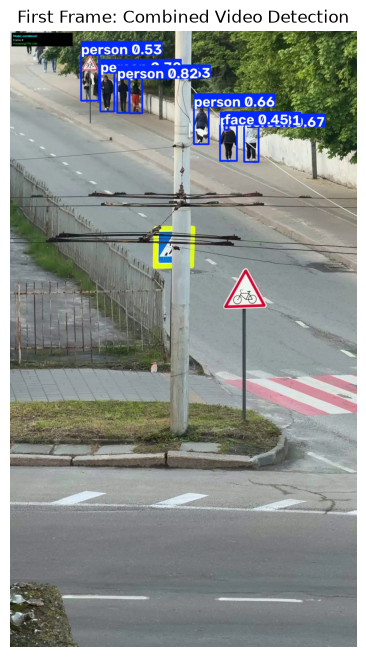

In [80]:
combined_capture = cv2.VideoCapture(
    str(combined_video_path)
)

try:
    success, combined_first_frame = (
        combined_capture.read()
    )

    if not success:
        raise RuntimeError(
            "Unable to read the first output frame."
        )

finally:
    combined_capture.release()

combined_first_frame_rgb = cv2.cvtColor(
    combined_first_frame,
    cv2.COLOR_BGR2RGB,
)

plt.figure(figsize=(14, 8))

plt.imshow(combined_first_frame_rgb)
plt.title("First Frame: Combined Video Detection")
plt.axis("off")

plt.show()

## 20. Troubleshooting

### 20.1 Input Video Cannot Be Opened

Possible causes:

- Incorrect file path.
- Unsupported video format.
- Corrupted input video.
- Missing video decoder support.

Solutions:

1. Verify the input path.
2. Test the video in a media player.
3. Check OpenCV video support.
4. Try another MP4 file.

### 20.2 Output Video Is Empty

Possible causes:

- VideoWriter failed to initialize.
- No input frames were decoded.
- Incorrect codec.
- Invalid output dimensions.

Solutions:

1. Check VideoWriter.isOpened().
2. Verify input video metadata.
3. Check the codec.
4. Confirm that processed frames match the writer dimensions.

### 20.3 Output Video Has No Annotations

Possible causes:

- No detections were produced.
- Confidence threshold is too high.
- The wrong model checkpoint was loaded.
- The input content is not supported by the model.

Check the detection DataFrame and test individual frames.

### 20.4 Processing Is Slow

Possible improvements:

1. Use a supported CUDA device.
2. Reduce YOLO inference size.
3. Process a shorter video for development.
4. Use a single detection model when appropriate.
5. Avoid unnecessary output operations.

### 20.5 Video Playback Is Not Working

Possible causes:

- Codec compatibility.
- Incomplete recording.
- Unsupported browser playback format.

Try opening the output in a desktop media player or using a different
supported video codec.

## 21. Exercises and Extension Challenges

### Beginner

1. Change the input video.
2. Inspect the metadata of another video.
3. Extract frames at different positions.
4. Run object-only detection.
5. Run face-only detection.
6. Run combined detection.

### Intermediate

7. Change confidence thresholds.
8. Compare processing FPS for different modes.
9. Export detection results to CSV.
10. Analyze confidence distributions.
11. Calculate detections per frame.
12. Process only the first 100 frames.

### Advanced

13. Implement frame skipping.
14. Add configurable output resolution.
15. Compare inference sizes of 320, 640, and 960.
16. Add a video progress indicator.
17. Add a command-line video-processing interface.
18. Implement batch processing for a directory of videos.

### Research Challenge

Investigate how input resolution, inference image size, model selection,
and hardware influence video-processing throughput.

Document the experimental conditions and actual measured results.

## 22. Key Learnings

This notebook introduced video-based computer vision.

Key concepts:

- Reading video files with OpenCV.
- Inspecting video metadata.
- Extracting individual video frames.
- Running YOLO inference on video frames.
- Performing separate object and face detection.
- Combining detection annotations.
- Writing annotated videos.
- Measuring processing FPS.
- Measuring model inference duration.
- Collecting detection statistics.
- Exporting results to CSV.
- Verifying output video files.

## 23. Conclusion

This notebook extended the detection pipeline from images and live webcams
to prerecorded video files.

Three processing modes were implemented:

1. General object detection.
2. Face detection.
3. Combined object and face detection.

The notebook also introduced video metadata inspection, frame extraction,
annotated video generation, performance analysis, and structured
detection exports.

The output videos can be used for demonstrations and further application
development.

The next notebook will focus on a more controlled performance comparison
between CPU and GPU execution.

## 24. References

- Ultralytics Documentation: https://docs.ultralytics.com/
- Ultralytics Python Usage: https://docs.ultralytics.com/usage/python/
- OpenCV Documentation: https://docs.opencv.org/
- OpenCV VideoCapture: https://docs.opencv.org/4.x/d8/dfe/classcv_1_1VideoCapture.html
- OpenCV VideoWriter: https://docs.opencv.org/4.x/dd/d9e/classcv_1_1VideoWriter.html
- PyTorch Documentation: https://pytorch.org/docs/stable/index.html
- NumPy Documentation: https://numpy.org/doc/
- Pandas Documentation: https://pandas.pydata.org/docs/
- Matplotlib Documentation: https://matplotlib.org/stable/

### Model Attribution

Document the verified source, authorship, and license of each model checkpoint.

Do not assume that both model checkpoints have identical training data,
architecture, or licensing terms.